# Steel Surface Defect Classification

Classification of six hot-rolled steel surface defect types using NEU-CLS. The benchmark compares a CNN trained from scratch with frozen and fine-tuned ImageNet-pretrained ResNet18 models under a fixed, stratified train/validation/test protocol.

NEU-CLS contains 1,800 grayscale 200 × 200 images, with 300 images per class. It does not include a healthy class. This project classifies defect types rather than predicting good-versus-defective status or bounding boxes.


## 0. Environment and data

Python 3.12, PyTorch 2.11.0+cu128, and Torchvision 0.26.0+cu128. The experiment uses an NVIDIA RTX 5070 Laptop GPU with 8 GiB VRAM. CUDA is required.

Extract the official NEU-CLS archive into `data/raw/`. Additional packages are listed in `requirements.txt`. The original grayscale images are kept outside version control. Pretrained ImageNet weights download on the first ResNet training run if uncached.


## 1. Imports

PyTorch provides training and CUDA computation; Torchvision provides ResNet18 and image transforms. Pillow handles image decoding, pandas organizes the manifest, scikit-learn supplies splitting and evaluation metrics, and Matplotlib produces the figures.


In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import random
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython import get_ipython
from PIL import Image, ImageOps
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

get_ipython().run_line_magic("matplotlib", "inline")


## 2. Experiment configuration

Fixed seed, 224 × 224 input, batch size 32, mixed precision, and CUDA-only execution. A saved run contains its split, best checkpoints, histories, and evaluation artifacts. Compatible checkpoints are reused; a new run name is required when changing the experiment.

`NUM_WORKERS = 0` supports Windows notebook execution. CPU image preprocessing is limited to four Torch threads to avoid oversubscription. Training and final evaluation can be disabled with their respective switches.


In [2]:
# Change this if Jupyter starts outside the project folder or its parent.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "requirements.txt").is_file():
    PROJECT_ROOT = PROJECT_ROOT / "steel_defect_classification"
if not (PROJECT_ROOT / "requirements.txt").is_file():
    raise FileNotFoundError("Set PROJECT_ROOT to the steel_defect_classification folder.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
SOURCE_GROUPS_PATH = PROJECT_ROOT / "data" / "source_groups.csv"
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
CPU_THREADS = 4
torch.set_num_threads(CPU_THREADS)
USE_AMP = True
RUN_TRAINING = True
RUN_FINAL_TEST = True
REUSE_CHECKPOINTS = True
RUN_NAME = "neu_cls_seed42_v1"
RUN_DIR = PROJECT_ROOT / "outputs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "crazing", "inclusion", "patches", "pitted_surface",
    "rolled_in_scale", "scratches",
]
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
CLASS_IDS = list(range(len(CLASS_NAMES)))
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select Python (RTX 5070 CUDA); CPU fallback is disabled.")
gpu_indices = [i for i in range(torch.cuda.device_count())
               if "RTX 5070" in torch.cuda.get_device_name(i)]
if not gpu_indices:
    raise RuntimeError("PyTorch cannot see the required RTX 5070 GPU.")
device = torch.device(f"cuda:{gpu_indices[0]}")
torch.cuda.set_device(device)
seed_everything(SEED)
# Prefer repeatable algorithm choices; exact results can still differ by platform/version.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

print("Python version:", __import__("sys").version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA runtime:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(device))
print("Device:", device, "| Run:", RUN_NAME, "| CPU threads:", CPU_THREADS)


Python version: 3.12.10
PyTorch: 2.11.0+cu128 | CUDA runtime: 12.8
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Device: cuda:0 | Run: neu_cls_seed42_v1 | CPU threads: 4


## 3. Image inventory

Labels are inferred from class folders or original filename prefixes. The manifest records image dimensions, label, relative path, and decoded-pixel SHA-256. Corrupt files and ambiguous labels stop processing.


In [3]:
ALIASES = {
    "cr": "crazing", "crazing": "crazing",
    "in": "inclusion", "inclusion": "inclusion",
    "pa": "patches", "patches": "patches",
    "ps": "pitted_surface", "pittedsurface": "pitted_surface",
    "rs": "rolled_in_scale", "rolledinscale": "rolled_in_scale",
    "sc": "scratches", "scratches": "scratches",
}
IMAGE_EXTENSIONS = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def compact_name(text):
    return re.sub(r"[^a-z0-9]", "", text.lower())

def infer_label(relative_path):
    path = Path(relative_path)
    candidates = {
        ALIASES[compact_name(part)]
        for part in path.parts[:-1]
        if compact_name(part) in ALIASES
    }
    stem = compact_name(path.stem)
    for alias, label in ALIASES.items():
        remainder = stem[len(alias):] if stem.startswith(alias) else ""
        if stem == alias or (remainder and remainder[0].isdigit()):
            candidates.add(label)
    if len(candidates) != 1:
        raise ValueError(f"Unknown or conflicting class for {relative_path}: {sorted(candidates)}")
    return next(iter(candidates))

def build_inventory(raw_dir):
    paths = sorted(p for p in raw_dir.rglob("*")
                   if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    if not paths:
        raise FileNotFoundError(f"Extract NEU-CLS images into {raw_dir} first.")
    rows, problems = [], []
    for path in paths:
        relative_path = path.relative_to(raw_dir).as_posix()
        try:
            label = infer_label(relative_path)
            with Image.open(path) as original:
                original.load()  # Surface corrupt or unreadable files now.
                image = ImageOps.exif_transpose(original).convert("L")
                digest = hashlib.sha256(
                    f"{image.width}x{image.height}:".encode() + image.tobytes()
                ).hexdigest()
                rows.append({
                    "relative_path": relative_path, "label": label,
                    "label_id": CLASS_TO_ID[label],
                    "width": image.width, "height": image.height,
                    "original_mode": original.mode, "pixel_sha256": digest,
                })
        except Exception as error:
            problems.append({"relative_path": relative_path, "error": str(error)})
    if problems:
        display(pd.DataFrame(problems))
        raise ValueError("Resolve the listed image/label problems before splitting.")
    frame = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    if set(frame["label"]) != set(CLASS_NAMES):
        raise ValueError("All six expected defect classes must be present.")
    return frame

inventory = build_inventory(RAW_DIR)
inventory.to_csv(RUN_DIR / "inventory.csv", index=False)
display(inventory.head())
display(inventory.groupby("label").size().reindex(CLASS_NAMES).rename("images").to_frame())
display(inventory.groupby(["width", "height"]).size().rename("images").to_frame())
if len(inventory) != 1800:
    warnings.warn(f"Found {len(inventory)} images; the original full NEU-CLS release has 1800.")


,relative_path,label,label_id,width,height,original_mode,pixel_sha256
0,NEU-CLS/Cr_1.bmp,crazing,0,200,200,L,7bededf883c9564d7d01cce7cfc3d7a995f7d4bb909b14...
1,NEU-CLS/Cr_10.bmp,crazing,0,200,200,L,3ab7d9b465355ba57128e23b261948d018390164e57fb1...
2,NEU-CLS/Cr_100.bmp,crazing,0,200,200,L,6d43db693d74232af05996c86952f5d419c93713c693fe...
3,NEU-CLS/Cr_101.bmp,crazing,0,200,200,L,c67347fc7640772cc65c0e630dd928e432102eaeab4858...
4,NEU-CLS/Cr_102.bmp,crazing,0,200,200,L,ca00f1227a283cfc29ba66b2c1921b36acf4e5d2516949...


,images
label,
crazing,300
inclusion,300
patches,300
pitted_surface,300
rolled_in_scale,300
scratches,300


,,images
width,height,
200,200,1800


## 4. Exploratory image inspection

Raw examples provide a visual check of class labels, image quality, texture variation, and acquisition artifacts before modeling.


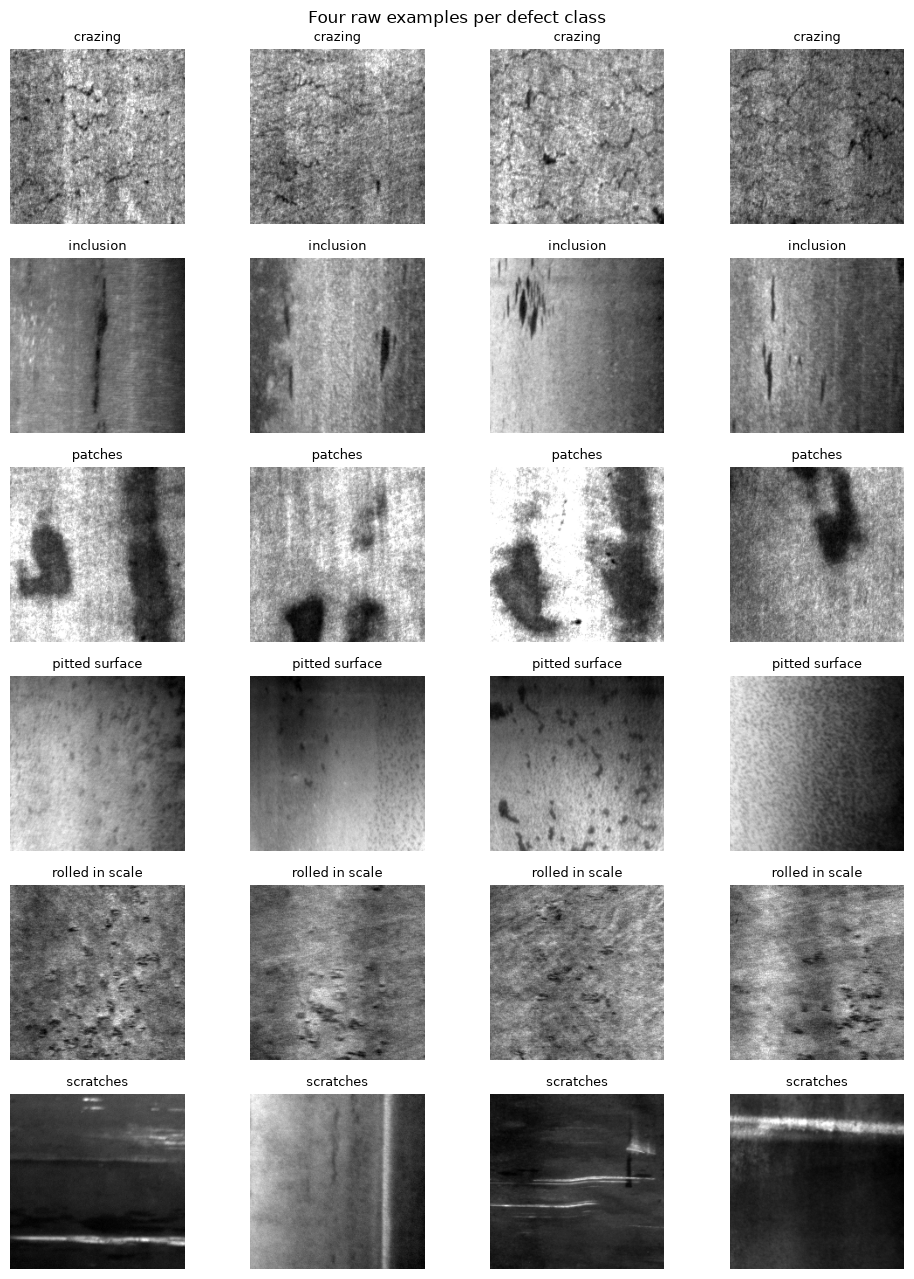

In [4]:
fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(10, 13))
for row, class_name in enumerate(CLASS_NAMES):
    examples = inventory[inventory["label"] == class_name].sample(
        n=min(4, int((inventory["label"] == class_name).sum())), random_state=SEED
    )
    for col in range(4):
        axes[row, col].axis("off")
        if col < len(examples):
            with Image.open(RAW_DIR / examples.iloc[col]["relative_path"]) as image:
                axes[row, col].imshow(image.convert("L"), cmap="gray")
            axes[row, col].set_title(class_name.replace("_", " "), fontsize=9)
fig.suptitle("Four raw examples per defect class")
fig.tight_layout()
fig.savefig(RUN_DIR / "raw_examples.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Duplicate and source checks

Exact decoded-pixel duplicates are reported and reduced to one same-label copy. Identical images with inconsistent labels require correction. If available, `data/source_groups.csv` maps every relative image path to a physical source group.

Without source metadata this is an image-level benchmark. Exact hashes cannot rule out adjacent crops, near-duplicates, or shared steel-strip origins.


In [5]:
conflicting_hashes = inventory.groupby("pixel_sha256")["label"].nunique()
if (conflicting_hashes > 1).any():
    bad_hashes = conflicting_hashes[conflicting_hashes > 1].index
    display(inventory[inventory["pixel_sha256"].isin(bad_hashes)])
    raise ValueError("Identical image pixels have conflicting labels; correct the data first.")

duplicate_rows = inventory[inventory.duplicated("pixel_sha256", keep=False)]
duplicate_rows.to_csv(RUN_DIR / "exact_duplicate_images.csv", index=False)
print("Images participating in exact-duplicate groups:", len(duplicate_rows))

inventory["source_group"] = inventory["pixel_sha256"]
HAS_SOURCE_GROUPS = SOURCE_GROUPS_PATH.is_file()
if HAS_SOURCE_GROUPS:
    groups = pd.read_csv(SOURCE_GROUPS_PATH, dtype=str)
    if not {"relative_path", "source_group"}.issubset(groups.columns):
        raise ValueError("source_groups.csv needs relative_path and source_group columns.")
    if groups[["relative_path", "source_group"]].isna().any().any():
        raise ValueError("Source paths and group IDs must not be missing.")
    groups["relative_path"] = groups["relative_path"].str.replace("\\", "/", regex=False)
    if groups["relative_path"].duplicated().any():
        raise ValueError("Each image needs exactly one source-group assignment.")
    if set(groups["relative_path"]) != set(inventory["relative_path"]):
        raise ValueError("Map every inventoried image exactly once; remove unknown paths.")
    inventory = inventory.drop(columns="source_group").merge(
        groups[["relative_path", "source_group"]],
        on="relative_path", how="left", validate="one_to_one",
    )
    # Conflicting source IDs for identical pixels can join otherwise separate groups.
    if (inventory.groupby("pixel_sha256")["source_group"].nunique() > 1).any():
        raise ValueError("Identical images map to different source groups; reconcile those IDs first.")

clean_images = (
    inventory.drop_duplicates("pixel_sha256", keep="first")
    .sort_values("relative_path").reset_index(drop=True)
)
print("Images retained:", len(clean_images))
print("Source-aware split:", HAS_SOURCE_GROUPS)


Images participating in exact-duplicate groups: 2
Images retained: 1799
Source-aware split: False


## 6. Fixed train, validation, and test partitions

Images are stratified into 70% training, 15% validation, and 15% test before augmentation. A saved fingerprint binds the split to paths, labels, pixel hashes, source IDs, and seed. Optional source grouping keeps each physical source within one partition and yields approximate split proportions.


In [6]:
fingerprint_payload = {
    "seed": SEED, "has_source_groups": HAS_SOURCE_GROUPS,
    "images": clean_images[["relative_path", "label", "pixel_sha256", "source_group"]].to_dict("records"),
}
DATA_FINGERPRINT = hashlib.sha256(
    json.dumps(fingerprint_payload, sort_keys=True).encode()
).hexdigest()
split_path = RUN_DIR / "splits.csv"
split_meta_path = RUN_DIR / "split_metadata.json"

if split_path.exists() or split_meta_path.exists():
    if not (split_path.exists() and split_meta_path.exists()):
        raise RuntimeError("Incomplete saved split; inspect it or choose a new RUN_NAME.")
    split_meta = json.loads(split_meta_path.read_text())
    if split_meta["data_fingerprint"] != DATA_FINGERPRINT:
        raise ValueError("Data/seed/grouping changed. Choose a new RUN_NAME to make a fresh split.")
    saved_split = pd.read_csv(split_path, dtype=str)
    if set(saved_split["relative_path"]) != set(clean_images["relative_path"]):
        raise ValueError("Saved split paths do not match the current inventory.")
    split_images = clean_images.merge(
        saved_split[["relative_path", "split"]], on="relative_path", validate="one_to_one"
    )
else:
    split_images = clean_images.copy()
    if HAS_SOURCE_GROUPS:
        if split_images["source_group"].nunique() < 20:
            raise ValueError("This 20-fold grouping recipe needs at least 20 independent source groups.")
        if split_images.groupby("label")["source_group"].nunique().min() < 3:
            raise ValueError("Every class needs at least three independent source groups.")
        splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
        fold_ids = np.full(len(split_images), -1, dtype=int)
        for fold, (_, held_indices) in enumerate(splitter.split(
            split_images, split_images["label_id"], groups=split_images["source_group"]
        )):
            fold_ids[held_indices] = fold
        split_images["split"] = np.where(
            fold_ids < 3, "test", np.where(fold_ids < 6, "validation", "train")
        )
    else:
        train_indices, hold_indices = train_test_split(
            np.arange(len(split_images)), test_size=0.30,
            stratify=split_images["label_id"], random_state=SEED,
        )
        validation_indices, test_indices = train_test_split(
            hold_indices, test_size=0.50,
            stratify=split_images.iloc[hold_indices]["label_id"], random_state=SEED,
        )
        split_images["split"] = "train"
        split_images.loc[validation_indices, "split"] = "validation"
        split_images.loc[test_indices, "split"] = "test"

if set(split_images["split"]) != {"train", "validation", "test"}:
    raise ValueError("The saved split needs exactly train, validation, and test partitions.")
if split_images.groupby("pixel_sha256")["split"].nunique().max() != 1:
    raise ValueError("Exact image duplicates cross partitions.")
if split_images.groupby("source_group")["split"].nunique().max() != 1:
    raise ValueError("Physical source groups cross partitions.")
for split_name in ["train", "validation", "test"]:
    if set(split_images.loc[split_images["split"] == split_name, "label"]) != set(CLASS_NAMES):
        raise ValueError(f"{split_name} is missing a class; revise the group-splitting design.")

split_images.to_csv(split_path, index=False)
split_meta_path.write_text(json.dumps({
    "data_fingerprint": DATA_FINGERPRINT, "seed": SEED,
    "has_source_groups": HAS_SOURCE_GROUPS,
}, indent=2))

train_df = split_images[split_images["split"] == "train"].reset_index(drop=True)
validation_df = split_images[split_images["split"] == "validation"].reset_index(drop=True)
test_df = split_images[split_images["split"] == "test"].reset_index(drop=True)
display(pd.crosstab(split_images["label"], split_images["split"]).reindex(CLASS_NAMES))
print("Train / validation / test:", len(train_df), len(validation_df), len(test_df))


split,test,train,validation
label,,,
crazing,45,210,45
inclusion,45,210,45
patches,45,209,45
pitted_surface,45,210,45
rolled_in_scale,45,210,45
scratches,45,210,45


Train / validation / test: 1259 270 270


## 7. Dataset and preprocessing

Grayscale intensities are replicated across three RGB channels, resized to 224 × 224, and normalized with ImageNet constants. All models receive the same preprocessing. Only training includes horizontal/vertical flips and mild brightness/contrast changes; the full image is retained to avoid cropping out defects.


In [7]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
TRANSFORM_SIGNATURE = {
    "train": repr(train_transform), "evaluation": repr(evaluation_transform),
}

class SteelDefectDataset(Dataset):
    def __init__(self, frame, raw_dir, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.raw_dir = Path(raw_dir)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.raw_dir / row["relative_path"]) as original:
            image = ImageOps.exif_transpose(original).convert("L").convert("RGB")
        image = self.transform(image)
        return image, int(row["label_id"])

def unnormalize(image_tensor):
    image = image_tensor.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)


## 8. Batched loading and augmentation inspection

Training batches shuffle within the fixed training partition. Validation and test preprocessing is deterministic, and evaluation loaders preserve image order. Batch tensors have shape `[N, 3, 224, 224]`; integer labels range from 0 to 5.


Image batch: torch.Size([32, 3, 224, 224]) torch.float32
Label batch: torch.Size([32]) torch.int64


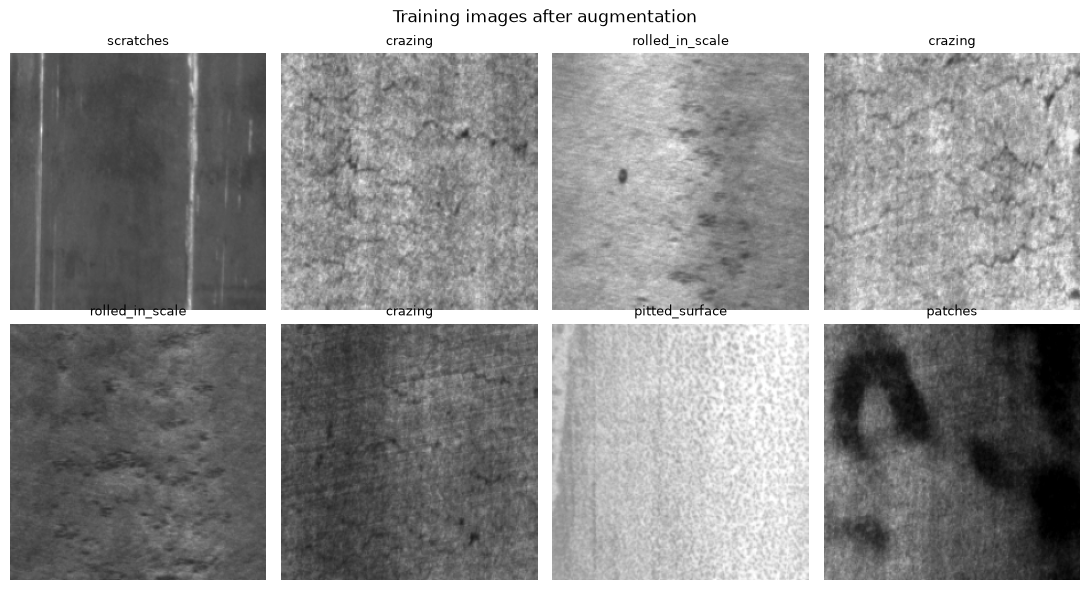

In [8]:
def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    train_dataset = SteelDefectDataset(train_df, RAW_DIR, train_transform)
    validation_dataset = SteelDefectDataset(validation_df, RAW_DIR, evaluation_transform)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=True, generator=generator,
    )
    validation_loader = DataLoader(
        validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
    )
    return train_loader, validation_loader

preview_loader, _ = make_loaders()
preview_images, preview_labels = next(iter(preview_loader))
print("Image batch:", preview_images.shape, preview_images.dtype)
print("Label batch:", preview_labels.shape, preview_labels.dtype)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for index, axis in enumerate(axes.flat):
    axis.axis("off")
    if index < len(preview_images):
        axis.imshow(unnormalize(preview_images[index]))
        axis.set_title(CLASS_NAMES[int(preview_labels[index])], fontsize=9)
fig.suptitle("Training images after augmentation")
fig.tight_layout()
fig.savefig(RUN_DIR / "augmented_examples.png", dpi=150, bbox_inches="tight")
plt.show()
del preview_loader, preview_images, preview_labels


## 9. Model architectures

The baseline contains three convolution/ReLU/pooling blocks, global average pooling, dropout, and a six-logit classifier. ResNet18 replaces its ImageNet classification layer with a six-class linear head. Cross-entropy consumes raw logits; probabilities are produced with softmax for evaluation.


In [9]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(), nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.25), nn.Linear(128, num_classes))

    def forward(self, images):
        return self.classifier(self.pool(self.features(images)))

def build_model(architecture, pretrained=False):
    if architecture == "small_cnn":
        return SmallCNN(num_classes=len(CLASS_NAMES))
    if architecture == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
        return model
    raise ValueError(f"Unknown architecture: {architecture}")

def configure_resnet(model, mode):
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.fc.parameters():
        parameter.requires_grad = True
    if mode == "last_block":
        for parameter in model.layer4.parameters():
            parameter.requires_grad = True
    elif mode != "head":
        raise ValueError("Use head or last_block for ResNet training.")


## 10. Training and evaluation loops

Training transfers the model and batches to CUDA and uses AdamW, automatic mixed precision, gradient scaling, and gradient clipping. Evaluation disables gradients. Frozen ResNet backbones remain in evaluation mode; BatchNorm running statistics also stay fixed during last-block fine-tuning.


In [10]:
def summarize_predictions(y_true, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "macro_f1": float(f1_score(y_true, predictions, labels=CLASS_IDS, average="macro", zero_division=0)),
        "macro_precision": float(precision_score(y_true, predictions, labels=CLASS_IDS, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, predictions, labels=CLASS_IDS, average="macro", zero_division=0)),
    }

def run_epoch(model, loader, optimizer=None, scaler=None, mode="full"):
    training = optimizer is not None
    model.train(training)
    if training and mode == "head":
        model.eval()
        model.fc.train()
    elif training and mode == "last_block":
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

    total_loss, total_images = 0.0, 0
    all_labels, all_probabilities = [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = nn.functional.cross_entropy(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], max_norm=5.0
                )
                scaler.step(optimizer)
                scaler.update()
        total_images += labels.numel()
        total_loss += float(loss.detach().cpu()) * labels.numel()
        all_labels.append(labels.detach().cpu().numpy())
        all_probabilities.append(torch.softmax(logits.detach().float(), dim=1).cpu().numpy())
    y_true = np.concatenate(all_labels)
    probabilities = np.concatenate(all_probabilities)
    metrics = summarize_predictions(y_true, probabilities)
    metrics["loss"] = total_loss / total_images
    return metrics, y_true, probabilities


## 11. Checkpointing and early stopping

The best checkpoint maximizes validation macro-F1, using validation loss to break ties. Early stopping limits training without inspecting test predictions. Histories record every completed epoch and its duration. Checkpoints retain weights, class order, preprocessing, split fingerprint, and experiment settings.


In [11]:
def read_checkpoint(path):
    checkpoint = torch.load(Path(path), map_location="cpu", weights_only=True)
    if checkpoint["data_fingerprint"] != DATA_FINGERPRINT:
        raise ValueError("Checkpoint belongs to different data or split settings.")
    if checkpoint["class_names"] != CLASS_NAMES or checkpoint["image_size"] != IMAGE_SIZE:
        raise ValueError("Checkpoint class order or image size differs from this configuration.")
    if checkpoint["mean"] != IMAGENET_MEAN or checkpoint["std"] != IMAGENET_STD:
        raise ValueError("Checkpoint normalization differs from this configuration.")
    if checkpoint["transform_signature"] != TRANSFORM_SIGNATURE:
        raise ValueError("Image transforms changed. Choose a new RUN_NAME.")
    return checkpoint

def run_experiment(name, architecture, epochs, patience, mode="full", initial_checkpoint=None):
    checkpoint_path = RUN_DIR / f"{name}.pt"
    if checkpoint_path.exists():
        if not REUSE_CHECKPOINTS:
            raise FileExistsError("Checkpoint exists. Choose a new RUN_NAME; files are not overwritten.")
        checkpoint = read_checkpoint(checkpoint_path)
        if checkpoint["architecture"] != architecture or checkpoint["training_mode"] != mode:
            raise ValueError("Checkpoint architecture/training phase differs from the requested experiment.")
        if (checkpoint["batch_size"] != BATCH_SIZE or checkpoint["max_epochs"] != epochs
                or checkpoint["used_amp"] != USE_AMP):
            raise ValueError("Training configuration changed. Choose a new RUN_NAME.")
        print(f"Reusing {name}, best epoch {checkpoint['best_epoch']}. Use a new RUN_NAME to retrain.")
        return checkpoint_path

    seed_everything(SEED)
    model = build_model(architecture, pretrained=(architecture == "resnet18" and initial_checkpoint is None))
    if initial_checkpoint is not None:
        previous = read_checkpoint(initial_checkpoint)
        model.load_state_dict(previous["model_state"])
        del previous
    if architecture == "resnet18":
        configure_resnet(model, mode)
    model = model.to(device)
    if next(model.parameters()).device != device:
        raise RuntimeError("The model is not on the required CUDA device.")

    if mode == "last_block":
        optimizer = torch.optim.AdamW([
            {"params": [p for p in model.layer4.parameters() if p.requires_grad], "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 5e-4},
        ], weight_decay=1e-4)
    else:
        optimizer = torch.optim.AdamW(
            [p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4
        )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    train_loader, validation_loader = make_loaders()
    best_score, best_loss, stale_epochs = -1.0, float("inf"), 0
    history = []
    torch.cuda.synchronize(device)
    phase_started = time.perf_counter()
    print(f"{name}: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable parameters")

    try:
        for epoch in range(1, epochs + 1):
            torch.cuda.synchronize(device)
            epoch_started = time.perf_counter()
            training_metrics, _, _ = run_epoch(model, train_loader, optimizer, scaler, mode)
            validation_metrics, _, _ = run_epoch(model, validation_loader)
            torch.cuda.synchronize(device)
            seconds = time.perf_counter() - epoch_started
            row = {"epoch": epoch, "epoch_seconds": seconds}
            row.update({f"train_{key}": value for key, value in training_metrics.items()})
            row.update({f"validation_{key}": value for key, value in validation_metrics.items()})
            history.append(row)
            pd.DataFrame(history).to_csv(RUN_DIR / f"{name}_history.csv", index=False)
            score, loss = validation_metrics["macro_f1"], validation_metrics["loss"]
            if not np.isfinite([training_metrics["loss"], loss, score]).all():
                raise RuntimeError("Non-finite loss/score. Inspect the data, lower the learning rate, or disable AMP in a new run.")
            improved = score > best_score + 1e-8 or (abs(score - best_score) <= 1e-8 and loss < best_loss)
            if improved:
                best_score, best_loss, stale_epochs = score, loss, 0
                torch.save({
                    "name": name, "architecture": architecture, "training_mode": mode,
                    "model_state": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
                    "class_names": CLASS_NAMES, "image_size": IMAGE_SIZE,
                    "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
                    "transform_signature": TRANSFORM_SIGNATURE,
                    "data_fingerprint": DATA_FINGERPRINT, "seed": SEED,
                    "best_epoch": epoch, "validation_metrics": validation_metrics,
                    "torch_version": str(torch.__version__), "batch_size": BATCH_SIZE,
                    "max_epochs": epochs, "used_amp": USE_AMP,
                    "phase_seconds": time.perf_counter() - phase_started,
                }, checkpoint_path)
            else:
                stale_epochs += 1
            mean_seconds = float(np.mean([item["epoch_seconds"] for item in history[-3:]]))
            remaining_minutes = mean_seconds * (epochs - epoch) / 60
            print(
                f"{name} {epoch:02d}/{epochs} | train loss {training_metrics['loss']:.3f} | "
                f"val loss {loss:.3f} | val macro-F1 {score:.3f} | {seconds:.1f}s | "
                f"remaining budget ~{remaining_minutes:.1f} min", flush=True,
            )
            if stale_epochs >= patience:
                print(f"Early stopping after {epoch} epochs.")
                break
        checkpoint = read_checkpoint(checkpoint_path)
        checkpoint["phase_seconds"] = time.perf_counter() - phase_started
        checkpoint["epochs_completed"] = len(history)
        torch.save(checkpoint, checkpoint_path)
        return checkpoint_path
    finally:
        del optimizer, scaler, model, train_loader, validation_loader
        gc.collect()
        torch.cuda.empty_cache()


## 12. Baseline CNN

Train all parameters from random initialization for up to 25 epochs, with early-stopping patience 6.


In [12]:
if RUN_TRAINING:
    run_experiment("baseline_cnn", "small_cnn", epochs=25, patience=6)
else:
    print("Training disabled. Set RUN_TRAINING=True in section 2 when ready.")


Reusing baseline_cnn, best epoch 21. Use a new RUN_NAME to retrain.


## 13. Frozen pretrained ResNet18

Train only the replacement classification head for up to 8 epochs, with patience 3. The ImageNet backbone and its BatchNorm statistics remain fixed.


In [13]:
if RUN_TRAINING:
    run_experiment("resnet18_frozen", "resnet18", epochs=8, patience=3, mode="head")
else:
    print("Frozen ResNet training disabled.")


Reusing resnet18_frozen, best epoch 8. Use a new RUN_NAME to retrain.


## 14. Last-block fine-tuning

Initialize from the best frozen-head checkpoint. Train `layer4` at learning rate 0.0001 and the classifier at 0.0005, for up to 12 epochs with patience 4. Earlier layers and BatchNorm running statistics remain fixed.


In [14]:
if RUN_TRAINING:
    frozen_path = RUN_DIR / "resnet18_frozen.pt"
    if not frozen_path.exists():
        raise FileNotFoundError("Run the frozen ResNet phase first.")
    run_experiment(
        "resnet18_finetuned", "resnet18", epochs=12, patience=4,
        mode="last_block", initial_checkpoint=frozen_path,
    )
else:
    print("ResNet fine-tuning disabled.")


Reusing resnet18_finetuned, best epoch 6. Use a new RUN_NAME to retrain.

## 15. Validation comparison and model selection

Compare the best checkpoint from each experiment using validation macro-F1, with lower validation loss breaking ties. Training curves show fit and overfitting behavior. The resulting selection is frozen before final test evaluation; test performance does not choose the model.


,model,best_epoch,epochs_completed,training_minutes,accuracy,macro_f1,macro_precision,macro_recall,loss
0,resnet18_finetuned,6,10,1.2451,1.0000,1.0000,1.0000,1.0000,0.0005
1,resnet18_frozen,8,8,0.9827,0.9889,0.9889,0.9891,0.9889,0.0715
2,baseline_cnn,21,25,3.1699,0.9259,0.9257,0.9274,0.9259,0.2094


Selected using validation only: resnet18_finetuned


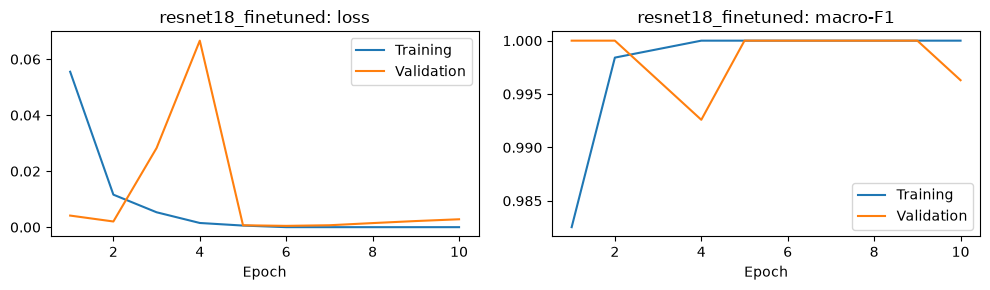

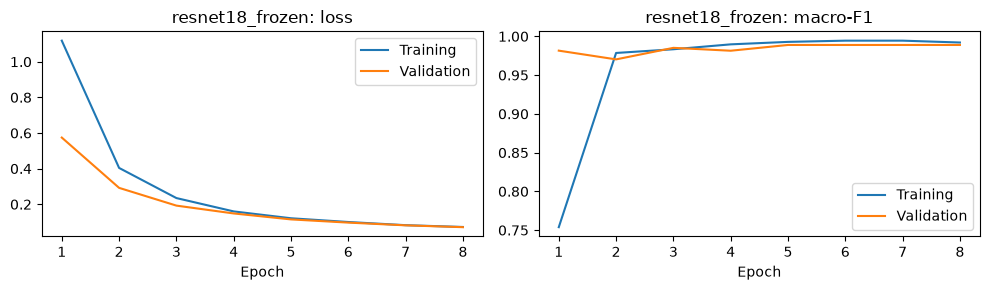

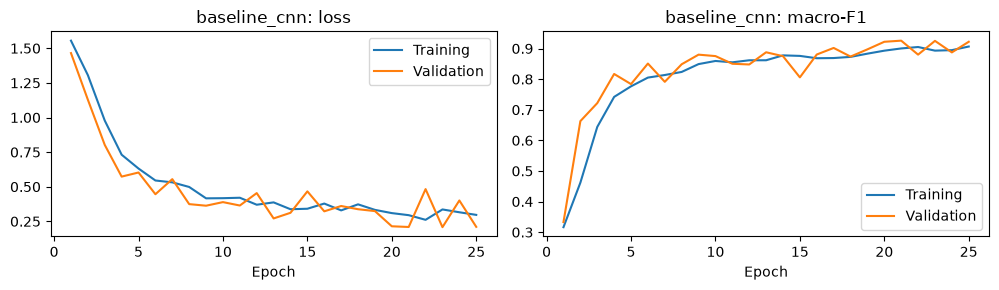

In [15]:
candidate_names = ["baseline_cnn", "resnet18_frozen", "resnet18_finetuned"]
validation_rows = []
for name in candidate_names:
    path = RUN_DIR / f"{name}.pt"
    if path.exists():
        checkpoint = read_checkpoint(path)
        validation_rows.append({
            "model": name, "best_epoch": checkpoint["best_epoch"],
            "epochs_completed": checkpoint.get("epochs_completed", checkpoint["best_epoch"]),
            "training_minutes": checkpoint["phase_seconds"] / 60,
            **checkpoint["validation_metrics"],
        })

selected_checkpoint = None
if validation_rows:
    validation_comparison = pd.DataFrame(validation_rows).sort_values(
        ["macro_f1", "loss", "model"], ascending=[False, True, True]
    ).reset_index(drop=True)
    display(validation_comparison.round(4))
    validation_comparison.to_csv(RUN_DIR / "validation_comparison.csv", index=False)
    selected_name = validation_comparison.iloc[0]["model"]
    selected_checkpoint = RUN_DIR / f"{selected_name}.pt"
    if len(validation_rows) < len(candidate_names):
        warnings.warn("Some experiments are missing; the current choice only compares available checkpoints.")
    print("Selected using validation only:", selected_name)
    for name in validation_comparison["model"]:
        history = pd.read_csv(RUN_DIR / f"{name}_history.csv")
        fig, axes = plt.subplots(1, 2, figsize=(10, 3))
        for prefix, label in [("train", "Training"), ("validation", "Validation")]:
            axes[0].plot(history["epoch"], history[f"{prefix}_loss"], label=label)
            axes[1].plot(history["epoch"], history[f"{prefix}_macro_f1"], label=label)
        axes[0].set_title(f"{name}: loss")
        axes[1].set_title(f"{name}: macro-F1")
        for axis in axes:
            axis.set_xlabel("Epoch")
            axis.legend()
        fig.tight_layout()
        fig.savefig(RUN_DIR / f"{name}_learning_curves.png", dpi=150)
        plt.show()
else:
    print("No trained checkpoints yet. Complete the training phases before selecting a model.")

# Enable this only after you have frozen the validation-selected model.
RUN_FINAL_TEST = True


## 16. Held-out test evaluation

Report accuracy, macro-F1, macro precision/recall, per-class precision/recall/F1/support, and raw-count and row-normalized confusion matrices. Rows represent true classes and columns represent predictions. Test outputs are saved for reproducible reporting.


,accuracy,macro_f1,macro_precision,macro_recall,loss
0,1.0,1.0,1.0,1.0,0.0025


,precision,recall,f1-score,support
crazing,1.0,1.0,1.0,45.0
inclusion,1.0,1.0,1.0,45.0
patches,1.0,1.0,1.0,45.0
pitted_surface,1.0,1.0,1.0,45.0
rolled_in_scale,1.0,1.0,1.0,45.0
scratches,1.0,1.0,1.0,45.0


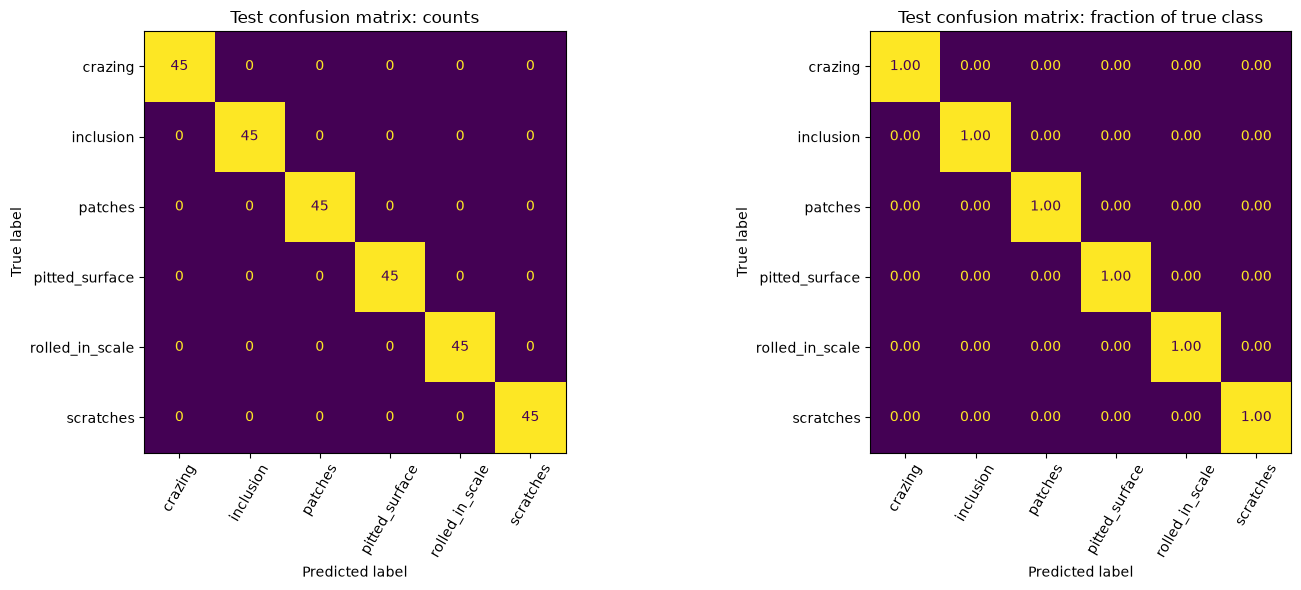

In [16]:
def load_model_for_inference(checkpoint_path):
    checkpoint = read_checkpoint(checkpoint_path)
    model = build_model(checkpoint["architecture"], pretrained=False)
    model.load_state_dict(checkpoint["model_state"])
    return model.to(device).eval(), checkpoint

final_model, test_predictions = None, None
if RUN_FINAL_TEST:
    if selected_checkpoint is None:
        raise RuntimeError("Train and select a checkpoint using validation first.")
    final_model, selected_metadata = load_model_for_inference(selected_checkpoint)
    test_loader = DataLoader(
        SteelDefectDataset(test_df, RAW_DIR, evaluation_transform),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,
    )
    test_metrics, test_true, test_probabilities = run_epoch(final_model, test_loader)
    test_predicted = test_probabilities.argmax(axis=1)
    report = classification_report(
        test_true, test_predicted, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    per_class_report = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
    display(pd.DataFrame([test_metrics]).round(4))
    display(per_class_report.round(4))
    per_class_report.to_csv(RUN_DIR / "test_classification_report.csv")
    (RUN_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))
    selection = {
        "model": selected_metadata["name"], "checkpoint": selected_checkpoint.name,
        "data_fingerprint": DATA_FINGERPRINT,
        "validation_metrics": selected_metadata["validation_metrics"],
    }
    (RUN_DIR / "selected_model.json").write_text(json.dumps(selection, indent=2))

    matrix = confusion_matrix(test_true, test_predicted, labels=CLASS_IDS)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / "test_confusion_matrix.csv")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=axes[0], xticks_rotation=60, colorbar=False, values_format="d"
    )
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    ConfusionMatrixDisplay(normalized, display_labels=CLASS_NAMES).plot(
        ax=axes[1], xticks_rotation=60, colorbar=False, values_format=".2f"
    )
    axes[0].set_title("Test confusion matrix: counts")
    axes[1].set_title("Test confusion matrix: fraction of true class")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "test_confusion_matrices.png", dpi=150, bbox_inches="tight")
    plt.show()

    test_predictions = test_df[["relative_path", "label"]].copy()
    test_predictions["predicted_label"] = [CLASS_NAMES[i] for i in test_predicted]
    test_predictions["confidence"] = test_probabilities.max(axis=1)
    test_predictions["correct"] = test_predictions["label"] == test_predictions["predicted_label"]
    for index, name in enumerate(CLASS_NAMES):
        test_predictions[f"probability_{name}"] = test_probabilities[:, index]
    test_predictions.to_csv(RUN_DIR / "test_predictions.csv", index=False)
else:
    print("Test evaluation disabled. Freeze your validation choice, then enable RUN_FINAL_TEST in section 15.")


## 17. Error analysis

Inspect one correct prediction per class, where available, and the two most confident mistakes. These final-test examples characterize the selected experiment; changes motivated by them would require a new independent final evaluation.


No errors in this test run; no mistaken example is available to display.


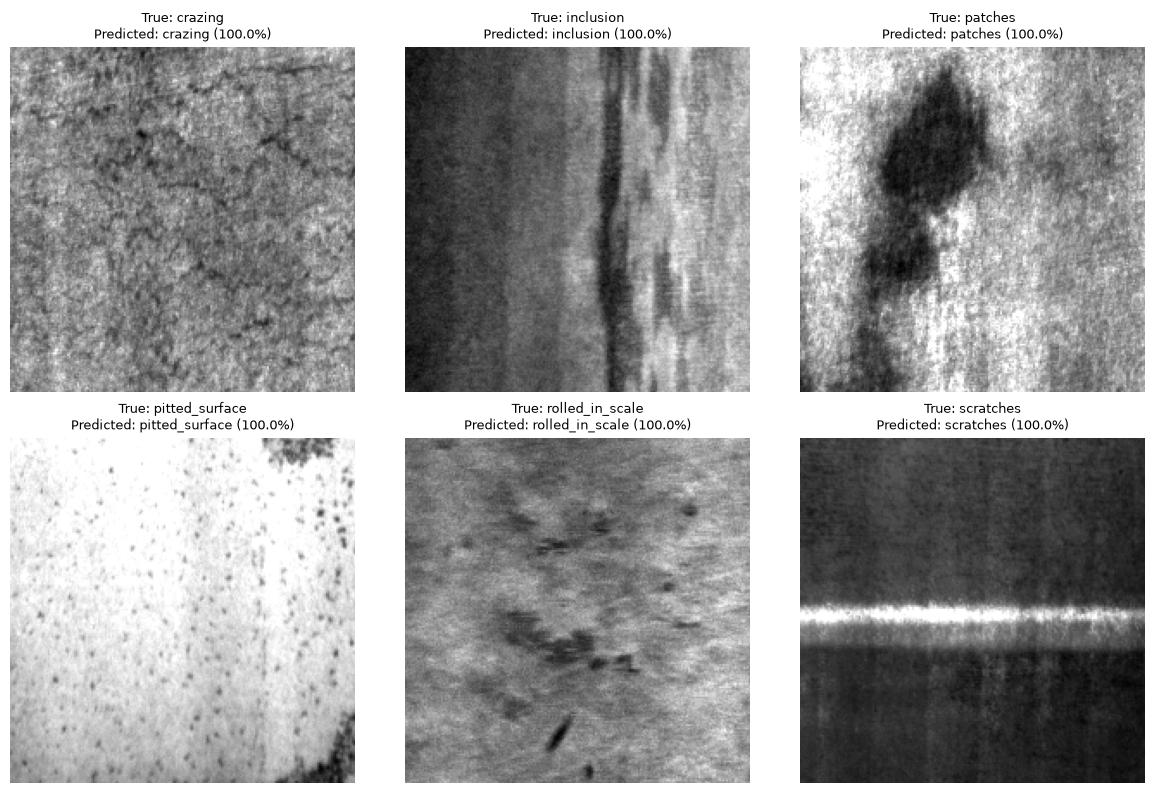

In [17]:
cam_examples = []
if test_predictions is not None:
    mistakes = test_predictions[~test_predictions["correct"]].sort_values("confidence", ascending=False)
    successes = test_predictions[test_predictions["correct"]].sort_values("relative_path")
    representatives = successes.drop_duplicates("label").set_index("label").reindex(CLASS_NAMES).dropna(subset=["relative_path"]).reset_index()
    cam_examples = [row for _, row in representatives.iterrows()]
    cam_examples += [row for _, row in mistakes.head(2).iterrows()]
    if mistakes.empty:
        print("No errors in this test run; no mistaken example is available to display.")
    columns = min(3, max(1, len(cam_examples)))
    rows = (len(cam_examples) + columns - 1) // columns
    fig, axes = plt.subplots(max(1, rows), columns, figsize=(4 * columns, 4 * max(1, rows)), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, row in zip(axes.flat, cam_examples):
        with Image.open(RAW_DIR / row["relative_path"]) as image:
            axis.imshow(image.convert("L"), cmap="gray")
        axis.set_title(f"True: {row['label']}\nPredicted: {row['predicted_label']} ({row['confidence']:.1%})", fontsize=9)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "test_example_predictions.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Run the final test evaluation before inspecting test predictions.")


## 18. Grad-CAM

Class-logit gradients weight the final spatial feature maps. The resulting positive-contribution map is resized onto the image. Explanations use full precision and enabled gradients, with hooks removed after each call.

The maps explain the predicted class by default. They are coarse visual explanations, not verified defect masks or proof of correct reasoning.


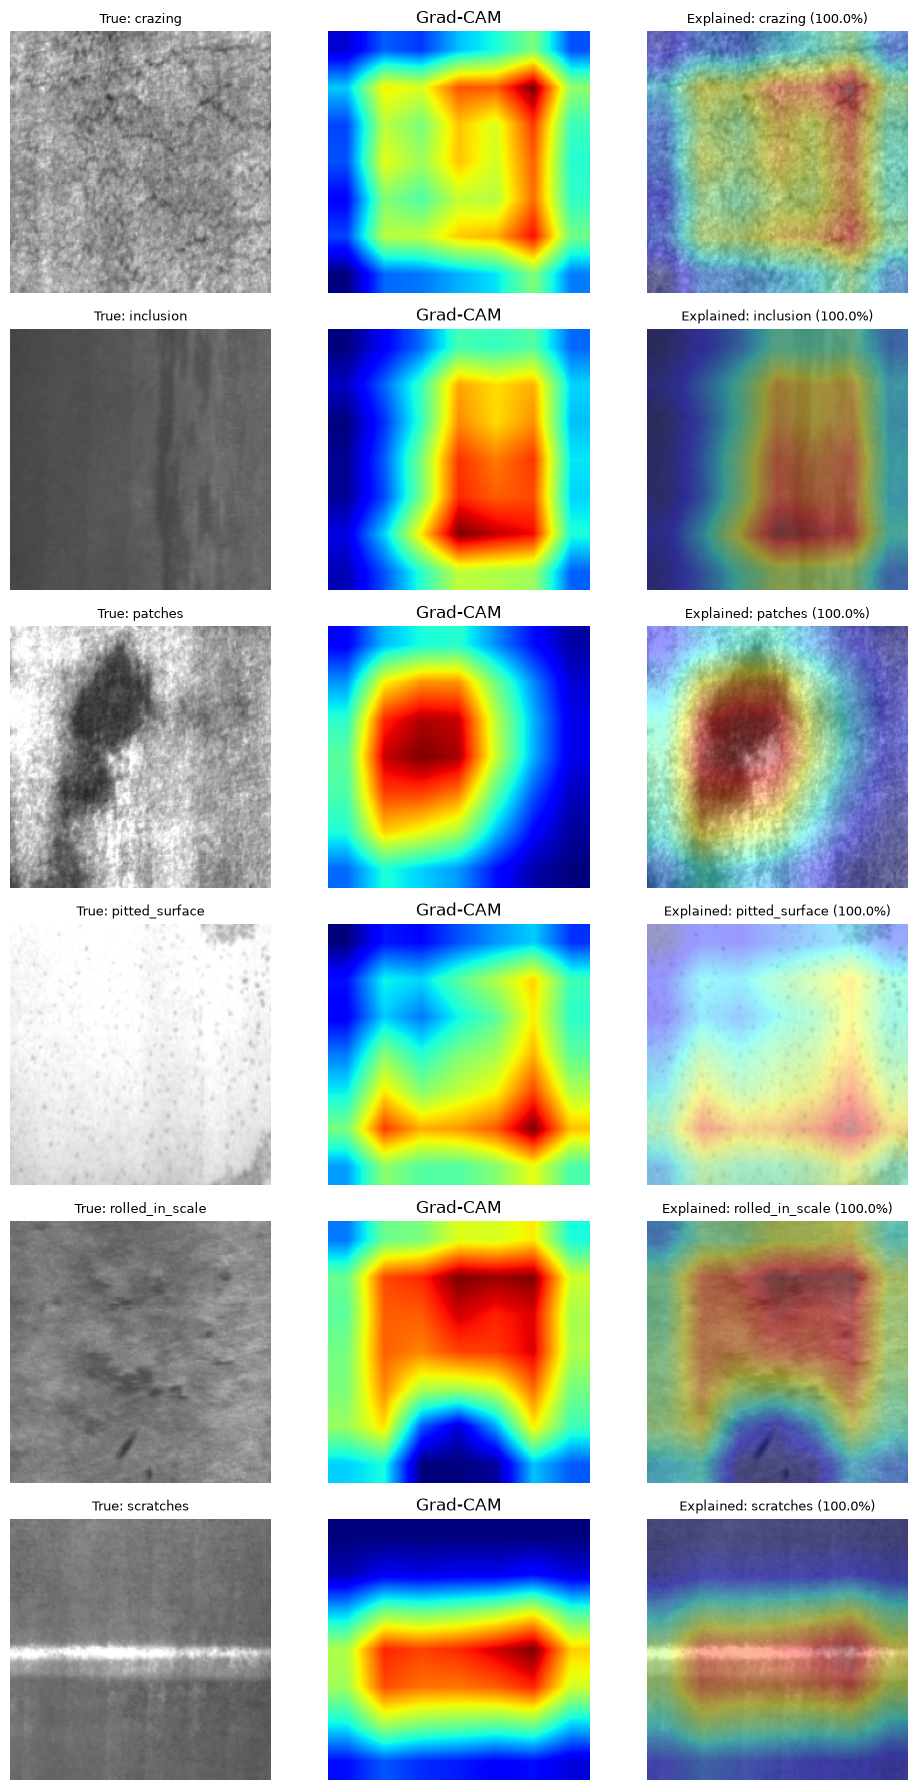

In [18]:
def make_gradcam(model, image_tensor, target_layer, class_id=None):
    captured = {}
    def forward_hook(module, inputs, output):
        captured["activations"] = output
        output.register_hook(lambda gradient: captured.__setitem__("gradients", gradient))

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()
    model.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            image = image_tensor.detach().clone().unsqueeze(0).to(device).requires_grad_(True)
            logits = model(image)
            target = int(logits.argmax(dim=1).item()) if class_id is None else int(class_id)
            if not 0 <= target < len(CLASS_NAMES):
                raise ValueError("Invalid Grad-CAM target class.")
            logits[0, target].backward()
            activations = captured["activations"].detach()
            gradients = captured["gradients"].detach()
            channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((channel_weights * activations).sum(dim=1, keepdim=True))
            cam = nn.functional.interpolate(cam, size=image.shape[-2:], mode="bilinear", align_corners=False)
            cam = cam[0, 0]
            cam = cam - cam.min()
            cam = cam / cam.max().clamp_min(1e-8)
            probability = float(torch.softmax(logits.detach(), dim=1)[0, target].cpu())
            return cam.cpu().numpy(), target, probability
    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

if final_model is not None and cam_examples:
    target_layer = (
        final_model.features[6]
        if selected_metadata["architecture"] == "small_cnn"
        else final_model.layer4[-1]
    )
    fig, axes = plt.subplots(len(cam_examples), 3, figsize=(10, 3 * len(cam_examples)), squeeze=False)
    for row_index, row in enumerate(cam_examples):
        with Image.open(RAW_DIR / row["relative_path"]) as original:
            image = ImageOps.exif_transpose(original).convert("L").convert("RGB")
        image_tensor = evaluation_transform(image)
        cam, class_id, probability = make_gradcam(final_model, image_tensor, target_layer)
        rgb = unnormalize(image_tensor)
        heatmap = plt.get_cmap("jet")(cam)[..., :3]
        overlay = np.clip(0.60 * rgb + 0.40 * heatmap, 0, 1)
        axes[row_index, 0].imshow(rgb)
        axes[row_index, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
        axes[row_index, 2].imshow(overlay)
        axes[row_index, 0].set_title(f"True: {row['label']}", fontsize=9)
        axes[row_index, 1].set_title("Grad-CAM")
        axes[row_index, 2].set_title(f"Explained: {CLASS_NAMES[class_id]} ({probability:.1%})", fontsize=9)
        for axis in axes[row_index]:
            axis.axis("off")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "gradcam_examples.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Grad-CAM needs the final model and evaluated examples. No explanation has been generated yet.")


## 19. Single-image inference

`predict_defect(image_path, checkpoint_path)` returns the predicted defect, softmax confidence, and six class probabilities using the checkpoint's class order and preprocessing. The demonstration uses a held-out image after final evaluation.

Healthy and unrelated images are still forced into one of the six known defect classes. Softmax confidence is not calibrated and does not detect unknown inputs.


In [19]:
def predict_defect(image_path, checkpoint_path):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(image_path)
    model, checkpoint = load_model_for_inference(checkpoint_path)
    try:
        with Image.open(image_path) as original:
            image = ImageOps.exif_transpose(original).convert("L").convert("RGB")
        batch = evaluation_transform(image).unsqueeze(0).to(device)
        with torch.inference_mode():
            probabilities = torch.softmax(model(batch).float(), dim=1)[0].cpu().numpy()
        best_index = int(probabilities.argmax())
        names = checkpoint["class_names"]
        return {
            "predicted_class": names[best_index],
            "confidence": float(probabilities[best_index]),
            "class_probabilities": {name: float(probabilities[i]) for i, name in enumerate(names)},
        }
    finally:
        del model
        torch.cuda.empty_cache()

RUN_PREDICTION_DEMO = True
NEW_IMAGE_PATH = RAW_DIR / test_df.iloc[0]["relative_path"]
if RUN_PREDICTION_DEMO:
    if selected_checkpoint is None:
        raise RuntimeError("Select a trained checkpoint first.")
    print(json.dumps(predict_defect(NEW_IMAGE_PATH, selected_checkpoint), indent=2))


{
  "predicted_class": "crazing",
  "confidence": 1.0,
  "class_probabilities": {
    "crazing": 1.0,
    "inclusion": 1.3432666700076402e-16,
    "patches": 1.6406892511255933e-09,
    "pitted_surface": 6.730611207261816e-11,
    "rolled_in_scale": 4.0246103671925937e-10,
    "scratches": 1.2183510155069043e-15
  }
}


## 20. Findings and limitations

The README reports measured validation and test results, model selection, elapsed training time, and observed error patterns. Interpret the small held-out set in the context of image-level splitting and unavailable physical-source metadata. A production inspection system would additionally require healthy examples, new acquisition sources, and source-independent evaluation.

### References

- [NEU surface defect database](https://faculty.neu.edu.cn/songkc/en/zdylm/263265/list/)
- [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [Grad-CAM](https://arxiv.org/abs/1610.02391)

Dataset citation: K. Song and Y. Yan, Applied Surface Science 285, 858–864, 2013.
